# Movie Recommendation System — TMDB 5000

Three recommenders built on the TMDB 5000 dataset, from simplest to most involved:

1. **Weighted average rating** — an IMDB-style score that discounts films with few votes
2. **Popularity ranking** — TMDB's own popularity metric
3. **Content-based filtering** — TF-IDF over plot summaries, ranked by pairwise similarity

The third one is what the deployed Streamlit app serves. The first two are the
baseline this was measured against, and they are what populate the charts below.

## Setup

In [ ]:
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, sigmoid_kernel
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Load and merge

Two files share a film id under different column names, so `movie_id` is renamed before the merge.

In [16]:
credits = pd.read_csv("tmdb_5000_credits.csv").rename(columns={"movie_id": "id"})
movies = pd.read_csv("tmdb_5000_movies.csv")

mix = movies.merge(credits, on="id")
mix = mix.drop(columns=["homepage", "title_x", "title_y", "production_countries", "status"])
mix.shape

(4803, 18)

## 2. Filter to films with enough votes

A rating built on 12 votes is noise. The 90th percentile of `vote_count` is the
cutoff, which keeps the 481 best-attested films out of 4,803.

The boxplot below is why a percentile was used rather than a round number — the
distribution is extremely long-tailed.

<Axes: xlabel='vote_count'>

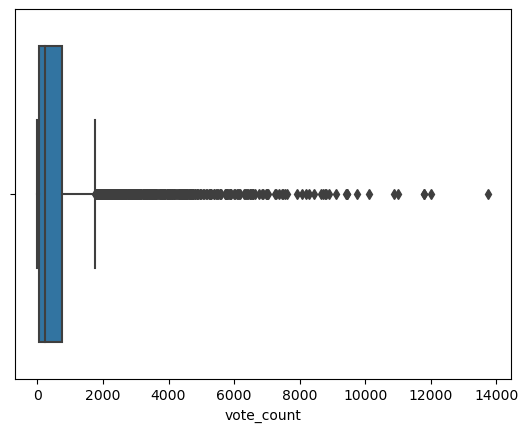

In [20]:
sns.boxplot(data=mix, x="vote_count")

In [22]:
tr = mix["vote_count"].quantile(q=0.9)
tr

In [ ]:
fltr = mix[mix["vote_count"] >= tr].copy()

# Reset the index so that row position and index label are the same number.
# Without this, `fltr` keeps the original TMDB row numbers (0..4602) while every
# matrix built from it is only 481x481 — indexing one with the other silently
# returns the wrong film, or raises IndexError. See section 5.
fltr = fltr.reset_index(drop=True)

print(f"cutoff {tr:.0f} votes -> {len(fltr)} films retained of {len(mix)}")

## 3. Weighted average rating

The IMDB formula, which pulls a film's own mean toward the global mean in
proportion to how few votes it has:

$$ \text{score} = \frac{R \cdot v + C \cdot m}{v + m} $$

`m` is a smoothing constant — the vote count at which a film's own rating begins
to outweigh the global mean. It is set just above the cutoff so that every film
in the set is still pulled toward the mean rather than trusted outright.

In [ ]:
m = 1900                                # smoothing constant, just above the 1838 cutoff
v = fltr["vote_count"]
R = fltr["vote_average"]
C = fltr["vote_average"].mean()         # global mean rating across the retained films

fltr["weighted_avg"] = ((R * v) + (C * m)) / (v + m)
print(f"global mean rating C = {C:.3f}")

In [33]:
top_ranks = fltr.sort_values("weighted_avg", ascending=False).head(20)
top_ranks[["original_title", "vote_count", "vote_average", "popularity", "weighted_avg"]]

,original_title,vote_count,vote_average,popularity,weighted_avg
1881,The Shawshank Redemption,8205,8.5,136.747729,8.211003
662,Fight Club,9413,8.3,146.757391,8.075452
3232,Pulp Fiction,8428,8.3,121.463076,8.054036
3337,The Godfather,5893,8.4,143.659698,8.049646
65,The Dark Knight,12002,8.2,187.322927,8.030937
96,Inception,13752,8.1,167.583710,7.961979
809,Forrest Gump,7927,8.2,138.133331,7.960831
95,Interstellar,10867,8.1,724.247784,7.930789
1990,The Empire Strikes Back,5879,8.2,78.517830,7.897865
1818,Schindler's List,4329,8.3,104.469351,7.892180


<Axes: xlabel='weighted_avg', ylabel='original_title'>

/Users/rishxbh/anaconda3/lib/python3.11/site-packages/IPython/core/events.py:93: UserWarning: Glyph 21315 (\N{CJK UNIFIED IDEOGRAPH-5343}) missing from current font.
  func(*args, **kwargs)
/Users/rishxbh/anaconda3/lib/python3.11/site-packages/IPython/core/events.py:93: UserWarning: Glyph 12392 (\N{HIRAGANA LETTER TO}) missing from current font.
  func(*args, **kwargs)
/Users/rishxbh/anaconda3/lib/python3.11/site-packages/IPython/core/events.py:93: UserWarning: Glyph 23563 (\N{CJK UNIFIED IDEOGRAPH-5C0B}) missing from current font.
  func(*args, **kwargs)
/Users/rishxbh/anaconda3/lib/python3.11/site-packages/IPython/core/events.py:93: UserWarning: Glyph 12398 (\N{HIRAGANA LETTER NO}) missing from current font.
  func(*args, **kwargs)
/Users/rishxbh/anaconda3/lib/python3.11/site-packages/IPython/core/events.py:93: UserWarning: Glyph 31070 (\N{CJK UNIFIED IDEOGRAPH-795E}) missing from current font.
  func(*args, **kwargs)
/Users/rishxbh/anaconda3/lib/python3.11/site-packages/IPython/core

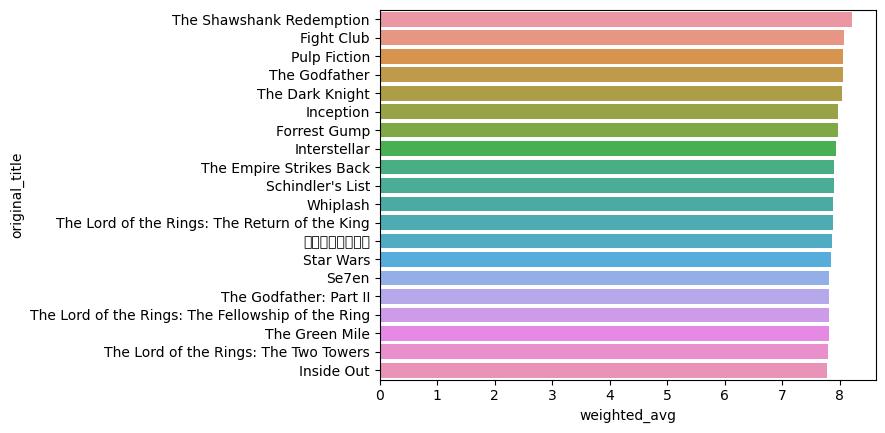

In [34]:
sns.barplot(x=top_ranks["weighted_avg"], y=top_ranks["original_title"])

## 4. Popularity ranking

TMDB's own popularity metric, for comparison. It rewards recency and attention rather than quality.

<Axes: ylabel='original_title'>

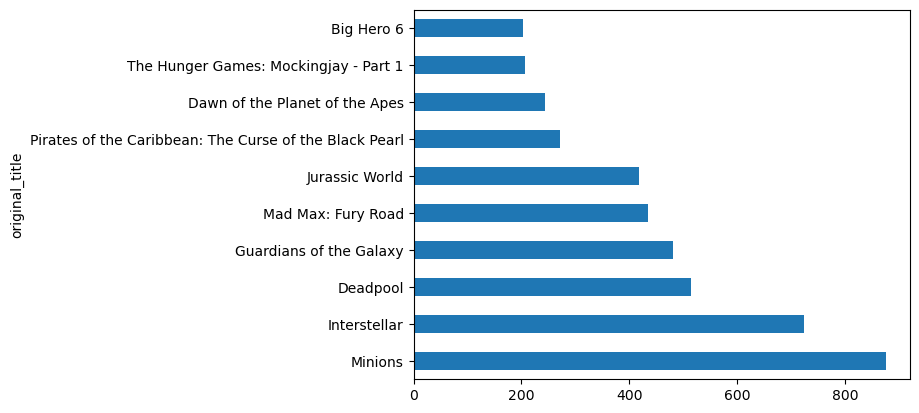

In [37]:
popu = fltr.sort_values("popularity", ascending=False)
popu.set_index("original_title")["popularity"][0:10].plot.barh()

### Normalising the two into a hybrid score

Rating and popularity live on different scales, so both are min-max scaled to
[0, 1] before being combined 50/50.

In [ ]:
fltr[["wt_sc", "pop_sc"]] = MinMaxScaler().fit_transform(fltr[["weighted_avg", "popularity"]])
fltr["combi_sc"] = fltr["wt_sc"] * 0.5 + fltr["pop_sc"] * 0.5

top_combo = fltr.sort_values("combi_sc", ascending=False).head(10)
top_combo[["original_title", "wt_sc", "pop_sc", "combi_sc"]]

In [ ]:
# (The original used plotly here. Its output embedded the whole plotly.js bundle —
# 3.7 MB, 89% of the notebook's file size — so it is seaborn now.)
ax = sns.barplot(x=top_combo["combi_sc"], y=top_combo["original_title"])
ax.set(xlabel="hybrid score", ylabel="")
plt.show()

## 5. Content-based filtering

The actual recommender. Each film's plot summary becomes a TF-IDF vector, and
films are ranked by pairwise similarity between those vectors.

`min_df=3` drops terms appearing in fewer than three summaries; `ngram_range=(1, 3)`
captures short phrases ("world war", "high school") rather than single words only.

In [55]:
tfv = TfidfVectorizer(min_df=3, max_features=None, ngram_range=(1, 3), stop_words="english")
tfv_matrix = tfv.fit_transform(fltr["overview"])
tfv_matrix

<481x1287 sparse matrix of type '<class 'numpy.float64'>'
	with 8196 stored elements in Compressed Sparse Row format>

In [59]:
sig = sigmoid_kernel(tfv_matrix, tfv_matrix)
sig

array([[0.76192028, 0.76159416, 0.76159416, ..., 0.76159416, 0.76159416,
        0.76159416],
       [0.76159416, 0.76192028, 0.76159416, ..., 0.76159416, 0.76159416,
        0.76159416],
       [0.76159416, 0.76159416, 0.76192028, ..., 0.76159416, 0.76159416,
        0.76159416],
       ...,
       [0.76159416, 0.76159416, 0.76159416, ..., 0.76192028, 0.7616054 ,
        0.76161335],
       [0.76159416, 0.76159416, 0.76159416, ..., 0.7616054 , 0.76192028,
        0.76159416],
       [0.76159416, 0.76159416, 0.76159416, ..., 0.76161335, 0.76159416,
        0.76192028]])

### A caveat on the sigmoid kernel

`sigmoid_kernel` computes $\tanh(\gamma \langle x, y \rangle + c_0)$ with
$c_0 = 1$ by default. TF-IDF dot products here are tiny, so every pair lands in a
band about $3 \times 10^{-4}$ wide around $\tanh(1) = 0.7616$ — the kernel is
**saturated**, and the ranking depends on the fourth decimal place.

Two things follow:

- the *values* are not interpretable as similarity scores and should not be shown to a user
- the matrix must stay `float64`; casting to `float32` reorders the top-10 for 26 of 481 films

The *ordering*, however, is sound. `tanh` is monotonic, so ranking by the sigmoid
kernel is equivalent to ranking by the dot product. Verified against cosine
similarity — the conventional choice for TF-IDF — below.

In [ ]:
cos = cosine_similarity(tfv_matrix, tfv_matrix)

overlap = np.array([
    len(set(np.argsort(-sig[i])[1:11]) & set(np.argsort(-cos[i])[1:11]))
    for i in range(len(sig))
])
print(f"sigmoid range: {sig.min():.6f} .. {sig.max():.6f}  (width {sig.max() - sig.min():.2e})")
print(f"cosine  range: {cos.min():.6f} .. {cos.max():.6f}  (width {cos.max() - cos.min():.2e})")
print(f"top-10 overlap: mean {overlap.mean():.2f}/10, identical for {(overlap == 10).sum()}/{len(sig)} films")

## 6. The recommender

`fltr` was reset in section 2, so `fltr.index` is row position and indexes `sig`
directly. The film's own row is the highest-scoring match against itself and is
excluded.

In [ ]:
def give_recc(movie_title, model, catalogue=None, n=10):
    """Return the n films most similar to `movie_title`."""
    catalogue = fltr if catalogue is None else catalogue
    indices = pd.Series(data=catalogue.index, index=catalogue["original_title"])
    idx = indices[movie_title]
    ranked = np.argsort(-model[idx])
    ranked = ranked[ranked != idx][:n]          # drop the film itself
    return catalogue["original_title"].iloc[ranked]

In [ ]:
give_recc("The Dark Knight", sig)

In [ ]:
give_recc("Toy Story", sig)

### Checking every film, not just a convenient one

The bug in the original version survived because it was only ever tested on
`"Avatar"` and `"John Carter"` — films at original index 0 and 2, inside the one
window where the stale index happened to equal row position. Ten of 481 films sat
in that window. The other 471 returned the wrong film or raised `IndexError`.

So: test all of them.

In [ ]:
failures = []
for title in fltr["original_title"]:
    try:
        res = give_recc(title, sig)
        if len(res) != 10 or title in set(res):
            failures.append(title)
    except Exception as exc:
        failures.append((title, repr(exc)))

print(f"{len(fltr)} films tested, {len(failures)} failures")
assert not failures

## 7. Export for the Streamlit app

Only two things need to ship: the titles **in matrix row order**, and the
similarity matrix. The `tfidf` vectoriser is not exported — it is only needed to
*build* the matrix, not to query it, so shipping it would add a scikit-learn
dependency to the app for nothing.

In [ ]:
catalogue = fltr[["original_title", "release_date", "vote_average", "vote_count", "overview"]].copy()
catalogue["year"] = pd.to_datetime(catalogue["release_date"], errors="coerce").dt.year
catalogue = catalogue.drop(columns=["release_date"])
catalogue.to_csv("data/movie_titles.csv", index=False)

# A plain ndarray, so np.save is enough — joblib would add a dependency and
# nothing else. float64 is deliberate, see section 5.
np.save("data/sigmoid_kernel.npy", sig)

print(f"saved {len(catalogue)} films and a {sig.shape} {sig.dtype} matrix "
      f"({sig.nbytes / 1e6:.2f} MB)")